# Inspection and exploration of public dataset from the Royer Lab 

(Lange et al., (2024). A multimodal zebrafish developmental atlas reveals the state-transition dynamics of late-vertebrate pluripotent axial progenitors. Cell, 187(23), 6742-6759.)

### The goal of this notebook is to inspect the data, understand the data structure and explore properties relevant for the next steps (segmentation, tracking)

### 1. Load packages

In [ ]:
import fsspec, zarr
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from functions import open_level, pink_fluor
from skimage.morphology import remove_small_objects
import pandas as pd
import json
PINK = "#d63384"     # hot pink
PLUM = "#7a1d6b"     # deep plum

### 2. Fetch data

In [2]:
## fetching the data from the Royer Lab public repository
## light sheet single objective recording of the developing zebrafish tail (ZSNS001_tail.ome.zarr)

URL = "https://public.czbiohub.org/royerlab/zebrahub/imaging/single-objective/ZSNS001_tail.ome.zarr"
    

### 3. inspect data structure and plot preview

0 (791, 1, 420, 1217, 1091) uint16 (1, 1, 128, 362, 362)
1 (791, 1, 210, 609, 546) uint16 (1, 1, 128, 362, 362)
2 (791, 1, 105, 305, 273) uint16 (1, 1, 105, 305, 273)


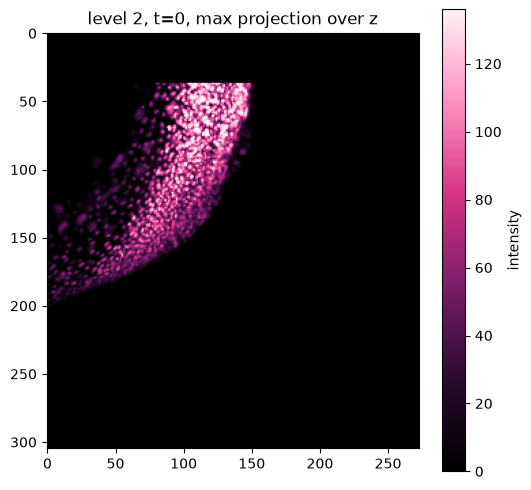

In [3]:
# available resolution levels
for lv in range(6):
    try:
        a = open_level(lv)
        print(lv, a.shape, a.dtype, a.chunks)
    except Exception:
        break

LEVEL = 2
a = open_level(LEVEL)
frame = np.asarray(a[0, 0])        # (z, y, x) at t=0
preview = frame.max(axis=0)        # max projection over z

# plotting with custom colormap
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(preview, cmap=pink_fluor, vmax=np.percentile(preview, 99.5))
ax.set_title(f"level {LEVEL}, t=0, max projection over z")
plt.colorbar(im, label="intensity")
plt.show()

### 4. Intensity range

In [4]:
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
T0, N_FRAMES = 0, 30
cache = DATA_DIR / f"zsns001_tail_L{LEVEL}_t{T0}-{T0+N_FRAMES}_maxz.npy"

if not cache.exists():
    frames = []
    for t in range(T0, T0 + N_FRAMES):
        vol = np.asarray(a[t, 0])            # (z, y, x)
        frames.append(vol.max(axis=0))       # max projection over z -> (y, x)
        print(f"frame {t} done", end="\r")
    np.save(cache, np.stack(frames))

stack = np.load(cache)
print(stack.shape)                           # expect (30, 305, 273)

(30, 305, 273)


uint16 (30, 305, 273)
min/max: 0 288
percentiles 1/50/99/99.9: [  0.   0. 121. 174.]
fraction at max value: 4.003282691807282e-07


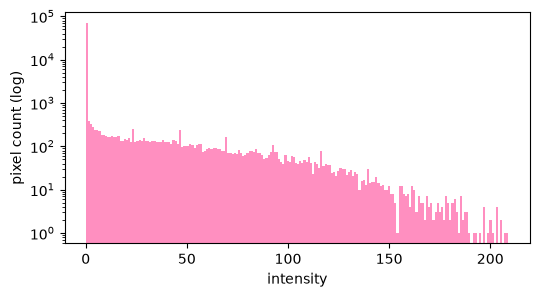

In [5]:
print(stack.dtype, stack.shape)
print("min/max:", stack.min(), stack.max())
print("percentiles 1/50/99/99.9:", np.percentile(stack, [1, 50, 99, 99.9]))
print("fraction at max value:", (stack == stack.max()).mean())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(stack[0].ravel(), bins=200, log=True, color="#ff8fc0")
ax.set_xlabel("intensity"); ax.set_ylabel("pixel count (log)")
plt.show()

fraction of zeros: 0.8341271842911188


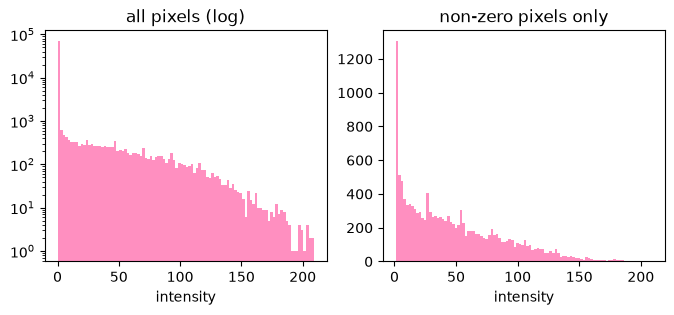

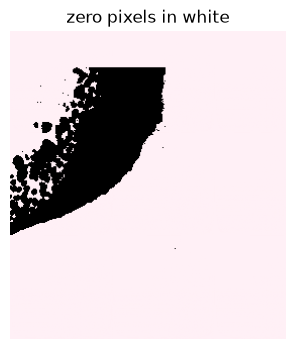

In [6]:
## check zeros

print("fraction of zeros:", (stack == 0).mean())

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].hist(stack[0].ravel(), bins=100, log=True, color="#ff8fc0")
axes[0].set_title("all pixels (log)")
axes[1].hist(stack[0][stack[0] > 0].ravel(), bins=100, color="#ff8fc0")
axes[1].set_title("non-zero pixels only")
for ax in axes: ax.set_xlabel("intensity")
plt.show()

plt.figure(figsize=(4, 4))
plt.imshow(stack[0] == 0, cmap=pink_fluor)
plt.title("zero pixels in white"); plt.axis("off"); plt.show()

bounding box: 34 205 0 167
(30, 171, 167)


/var/folders/t8/t9md_f8j7370t6vc2x4wj8bx9396jn/T/ipykernel_65636/678662462.py:3: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  tissue = remove_small_objects(tissue, min_size=200)


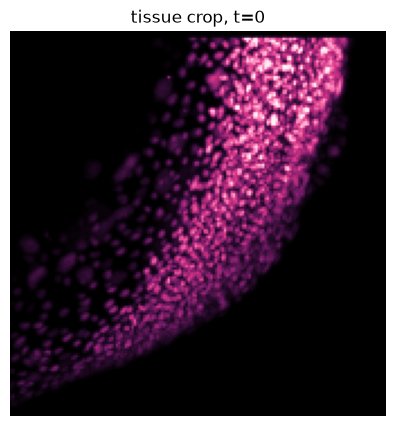

In [7]:
# crop image to tissue region, removing small obecjts
tissue = (stack > 0).any(axis=0)                 # nonzero in any frame
tissue = remove_small_objects(tissue, min_size=200)

ys, xs = np.where(tissue)
y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
print("bounding box:", y0, y1, x0, x1)

crop = stack[:, y0:y1, x0:x1]
print(crop.shape)

vmax = np.percentile(crop[crop > 0], 99.5)
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(crop[0], cmap=pink_fluor, vmin=0, vmax=vmax)
ax.set_title("tissue crop, t=0"); ax.axis("off")
plt.show()

In [8]:
inside = tissue[y0:y1, x0:x1]
vals = crop[:, inside]                  # (frames, pixels inside tissue)
print("inside tissue: mean", vals.mean(), "| 50/90/99 pct", np.percentile(vals, [50, 90, 99]))

inside tissue: mean 39.34897562523552 | 50/90/99 pct [ 28. 100. 160.]


#### 5. intensity over time

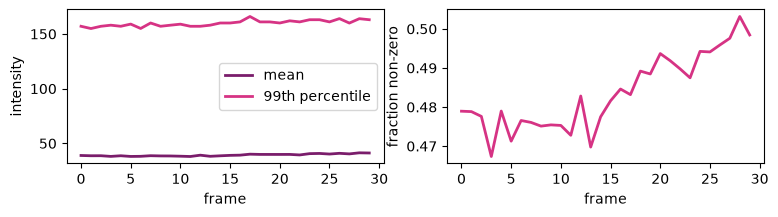

In [9]:
# intensity and non-0 fraction over 30 frames

mean_t = np.array([c[inside].mean() for c in crop])
p99_t = np.array([np.percentile(c[inside], 99) for c in crop])
frac_t = np.array([(c > 0).mean() for c in crop])

fig, axes = plt.subplots(1, 2, figsize=(9, 2))
axes[0].plot(mean_t, color=PLUM, lw=2, label="mean")
axes[0].plot(p99_t, color=PINK, lw=2, label="99th percentile")
axes[0].set_xlabel("frame"); axes[0].set_ylabel("intensity"); axes[0].legend()
axes[1].plot(frac_t, color=PINK, lw=2)
axes[1].set_xlabel("frame"); axes[1].set_ylabel("fraction non-zero")
plt.show()

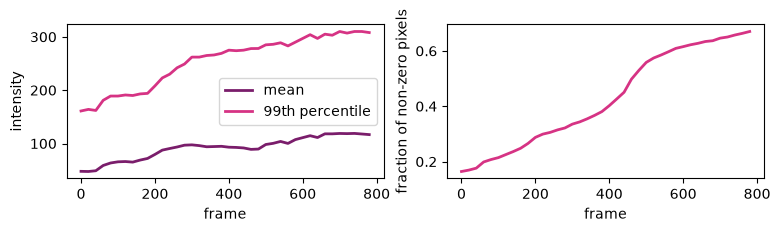

In [12]:
# intensity and non-0 fraction over all frames sampling every 20 frames
STEP = 20      

# fetch csv if it exists, otherwise compute
csv = DATA_DIR / "intensity_over_time.csv"
if csv.exists():
    df = pd.read_csv(csv)
else:
    rows = []
    for t in range(0, a.shape[0], STEP):
        mp = np.asarray(a[t, 0]).max(axis=0)
        nz = mp[mp > 0]
        rows.append(dict(t=t, mean=nz.mean(), p99=np.percentile(nz, 99),
                         frac_nonzero=(mp > 0).mean()))
    df = pd.DataFrame(rows)
    df.to_csv(csv, index=False)

df = pd.DataFrame(rows)
df.to_csv(DATA_DIR / "intensity_over_time.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(9, 2))
axes[0].plot(df.t, df["mean"], color=PLUM, lw=2, label="mean")
axes[0].plot(df.t, df["p99"], color=PINK, lw=2, label="99th percentile")
axes[0].set_xlabel("frame"); axes[0].set_ylabel("intensity"); axes[0].legend()
axes[1].plot(df.t, df["frac_nonzero"], color=PINK, lw=2)
axes[1].set_xlabel("frame"); axes[1].set_ylabel("fraction of non-zero pixels")
plt.show()

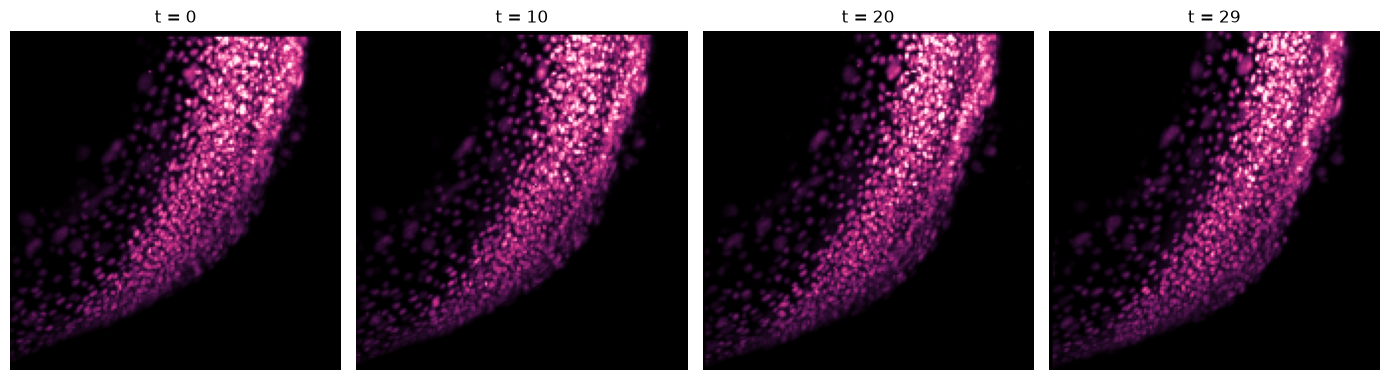

In [13]:
idx = [0, 10, 20, 29]
vmax = np.percentile(crop[crop > 0], 99.5)      # one shared scale for all panels

fig, axes = plt.subplots(1, len(idx), figsize=(14, 4))
for ax, i in zip(axes, idx):
    ax.imshow(crop[i], cmap=pink_fluor, vmin=0, vmax=vmax)
    ax.set_title(f"t = {T0 + i}"); ax.axis("off")
plt.tight_layout(); plt.show()

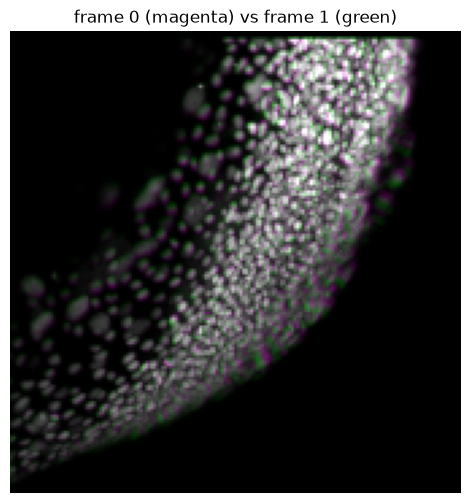

In [14]:
# visual: magenta = frame 0, green = frame 1, white = overlap
vmax2 = np.percentile(crop[:2][crop[:2] > 0], 99.5)
rgb = np.stack([crop[0], crop[1], crop[0]], axis=-1).astype(float) / vmax2
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(np.clip(rgb, 0, 1)); ax.axis("off")
ax.set_title("frame 0 (magenta) vs frame 1 (green)")
plt.show()

In [15]:
# quantitative: distance from each peak in frame 0 to its nearest peak in frame 1
from skimage import filters, feature
from scipy.spatial import cKDTree

def get_peaks(img, sigma=2, min_distance=2, threshold_abs=30):
    sm = filters.gaussian(img.astype(float), sigma=sigma)
    return feature.peak_local_max(sm, min_distance=min_distance,
                                  threshold_abs=threshold_abs,
                                  labels=inside.astype(int))

p0, p1 = get_peaks(crop[0]), get_peaks(crop[1])
dist, _ = cKDTree(p1).query(p0)
print("peaks:", len(p0), len(p1))
print("nearest-neighbour shift (px): median %.1f | 90th %.1f | 95th %.1f"
      % (np.median(dist), *np.percentile(dist, [90, 95])))

peaks: 62 61
nearest-neighbour shift (px): median 1.0 | 90th 4.4 | 95th 6.4


In [ ]:
# save metadata as json
meta = dict(level=LEVEL, t0=T0, n_frames=N_FRAMES,
            bbox_y=[int(y0), int(y1)], bbox_x=[int(x0), int(x1)],
            projection="max over z", source=URL)
json.dump(meta, open(DATA_DIR / "crop_meta.json", "w"), indent=2)

In [11]:
np.save(DATA_DIR / "crop_stack.npy", crop)
np.save(DATA_DIR / "tissue_mask.npy", inside)